In [ ]:
%load_ext autoreload
%autoreload 2

#!pip install graphviz

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
Using cached graphviz-0.21-py3-none-any.whl (47 kB)


In [11]:
from dataclasses import dataclass
import numpy as np
from typing import Any, List, Callable
from collections import defaultdict
from mdp import Policy, MDP, Step, Rollout, FlackyTramMDP, RLAlgorithm, walk_tram_exploration_policy, simulate
from functools import partial
import torch 
import torch.nn as nn

def one_hot(index: int, num_classes: int) -> torch.Tensor:
    v = torch.zeros(num_classes)
    v[index] = 1.0
    return v

print(one_hot(1, 10))
np.random.seed(42)
torch.random.manual_seed(42)
tram_mdp = FlackyTramMDP(num_locs=10, failure_prob=0.4)

tensor([0., 1., 0., 0., 0., 0., 0., 0., 0., 0.])


In [30]:
class LinearQLearning(RLAlgorithm):
    def __init__(
            self, 
            num_locs: int,
            actions: List[str],
            exploration_policy: Policy, 
            exploration_prob = 0.4, 
            epsilon_decay: float = 0.99, 
            lr: float = 0.01, 
            discount: float = 1.0):
        self.exploration_policy = exploration_policy
        self.epsilon = exploration_prob
        self.epsilon_decay = epsilon_decay
        self.lr = lr
        self.num_locs = num_locs
        self.actions = actions
        self.discount = discount
        self.num_features = self.get_num_features()
        # θ：Q_θ(s, a) = θ · φ(s, a)
        self.model = nn.Linear(self.num_features, 1, bias=False)
        self.optimizer = torch.optim.SGD(self.model.parameters(), lr)

    def get_num_features(self):
        raise NotImplementedError
     
    def phi(self, state: int, action: str) -> torch.Tensor:
        raise NotImplementedError

    def Q(self, state: int, action: str) -> torch.Tensor:
        return self.model(self.phi(state, action))

    def pi(self, state: int) -> str:
        q_values = { action : self.Q(state, action) for action in self.actions}
        return max(q_values.keys(), key=lambda s: q_values[s].item())

    def get_action(self, state: int) -> str:
        if torch.rand(1).item() < self.epsilon:
            return self.exploration_policy(state)
        else:
            return self.pi(state)
        
    def incorporate_feedback(self, state: int, action: str, reward: float, next_state: int, is_end: bool):
        # Q-learning update (Loss & SGD Step)
        if is_end:
            target = reward
        else:
            next_action = self.pi(next_state)
            # Bootstrapping：target = r + γ * max_{a'} Q(s', a')
            # Use .detach() to prevent backprops on target
            target = reward + self.discount * self.Q(next_state, next_action).detach()

        value = self.Q(state, action)
        # use squared loss: Loss = (Q(s,a) - target)^2
        loss = (value - target) ** 2
        # Update model with a gradient step
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        # if is_end:
        #     self.epsilon *= self.epsilon_decay # Exploration prob decay

In [31]:
class IndicatorLinearQLearning(LinearQLearning):
    
    def get_num_features(self):
        return self.num_locs * len(self.actions)
    
    def phi(self, state: int, action: str) -> torch.Tensor:
        index = (state - 1) * len(self.actions) + self.actions.index(action)
        return one_hot(index, self.num_features)


class DoublingsLinearQLearning(LinearQLearning):

    def get_num_features(self):
        return 2 * len(self.actions)

    def phi(self, state: int, action: str) -> torch.Tensor:
        # actions one hot vector (size = #actions)
        actions_indicator = one_hot(self.actions.index(action), len(self.actions))

        # d(s) = log2(N / s)
        doublings = np.log2(self.num_locs / max(state, 1))

        # concat actions + d(x): [1[a=walk], 1[a=tram], 1[a=walk]*d(s), 1[a=tram]*d(s)]
        vector = torch.cat([actions_indicator, actions_indicator * doublings])
        return vector.float()

In [20]:
# Test IndicatorLinearQLearning
exploration_policy = partial(walk_tram_exploration_policy, tram_mdp.num_locs)
rl = IndicatorLinearQLearning(tram_mdp.num_locs, ["walk", "tram"], exploration_policy, exploration_prob=0.4, lr=0.1, discount=0.9)
scores = simulate(tram_mdp, rl, num_trials=200)
print(f"[Linear Q-Learning] mean utility: {np.mean(scores):.2f}")
print("Policy Learned π(s):", {s: rl.pi(s) for s in range(1, tram_mdp.num_locs + 1)})

[Linear Q-Learning] mean utility: -6.95
Policy Learned π(s): {1: 'walk', 2: 'walk', 3: 'walk', 4: 'walk', 5: 'tram', 6: 'walk', 7: 'walk', 8: 'walk', 9: 'walk', 10: 'walk'}


In [36]:
# Test DoublingsLinearQLearning
exploration_policy = partial(walk_tram_exploration_policy, tram_mdp.num_locs)
rl = DoublingsLinearQLearning(tram_mdp.num_locs, ["walk", "tram"], exploration_policy, exploration_prob=0.4, lr=0.1, discount=0.9)
scores = simulate(tram_mdp, rl, num_trials=200)
print(f"[Linear Q-Learning] mean utility: {np.mean(scores):.2f}")
print("Policy Learned π(s):", {s: rl.pi(s) for s in range(1, tram_mdp.num_locs + 1)})

[Linear Q-Learning] mean utility: -7.46
Policy Learned π(s): {1: 'tram', 2: 'tram', 3: 'tram', 4: 'walk', 5: 'walk', 6: 'walk', 7: 'walk', 8: 'walk', 9: 'walk', 10: 'walk'}


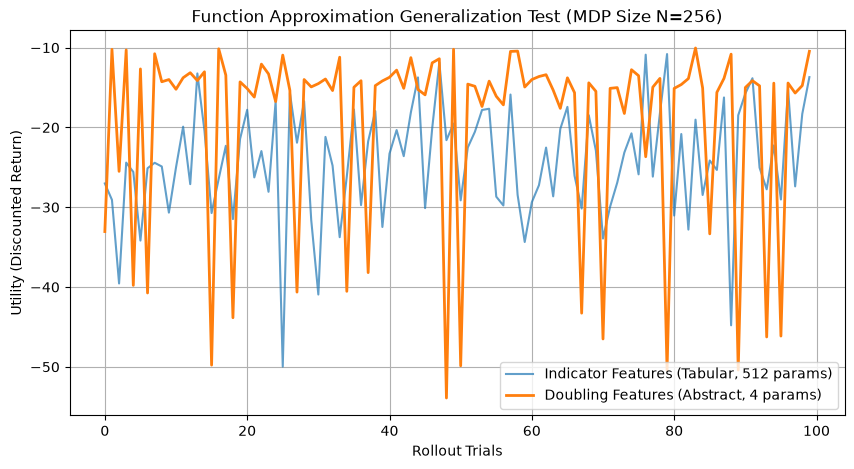

Indicator 参数总数:512
Doubling 参数总数:4
Doubling 模型在 State 10 的策略选择: tram
Doubling 模型在 State 200 的策略选择: walk


In [37]:
from matplotlib import pyplot as plt

# 运行长距离环境 (N=256) 的对比实验与绘图
LARGE_N = 256
env_large = FlackyTramMDP(num_locs=LARGE_N, failure_prob=0.1) 
actions = ["walk", "tram"]
num_trials = 100

# 1. 训练 Indicator/Tabular Agent
agent_indicator = IndicatorLinearQLearning(num_locs=LARGE_N, actions=actions, exploration_policy=exploration_policy, lr=0.1)
rewards_indicator = simulate(env_large, agent_indicator, num_trials=num_trials)

# 2. 训练 Doubling/Abstract Feature Agent
agent_doubling = DoublingsLinearQLearning(num_locs=LARGE_N, actions=actions, exploration_policy=exploration_policy, lr=0.005)
rewards_doubling = simulate(env_large, agent_doubling, num_trials=num_trials)

# 绘图对比
plt.figure(figsize=(10, 5))
plt.plot(rewards_indicator, label="Indicator Features (Tabular, 512 params)", alpha=0.7)
plt.plot(rewards_doubling, label="Doubling Features (Abstract, 4 params)", linewidth=2)
plt.xlabel("Rollout Trials")
plt.ylabel("Utility (Discounted Return)")
plt.title(f"Function Approximation Generalization Test (MDP Size N={LARGE_N})")
plt.legend()
plt.grid(True)
plt.show()

# 输出特征维度与学到的策略示例
print(f"Indicator 参数总数:{agent_indicator.num_features}")
print(f"Doubling 参数总数:{agent_doubling.num_features}")
print("Doubling 模型在 State 10 的策略选择:", agent_doubling.pi(10))
print("Doubling 模型在 State 200 的策略选择:", agent_doubling.pi(200))